Evaluating reinforcement learning (RL) models is distinct from supervised or unsupervised learning due to the sequential decision-making nature of RL. Here's a breakdown of key metrics and considerations:

# Key Metrics:

## Cumulative Reward:
This is the most fundamental metric. It's the total reward an agent accumulates over an episode or a series of episodes.
It directly reflects how well the agent is achieving its goal.
## Average Reward:
This provides a more stable measure, especially when episode lengths vary.
It's calculated by averaging the rewards obtained per time step or per episode.
## Discounted Cumulative Reward:
In many RL scenarios, future rewards are discounted. This metric accounts for the time value of rewards.
It's useful for evaluating how well an agent balances immediate and long-term rewards.
## Episode Length:
The number of steps an agent takes to complete an episode.
It can indicate the efficiency of the agent's policy.
## Success Rate:
In tasks with a clear definition of success or failure, this metric measures the percentage of episodes where the agent achieves the goal.
## Sample Efficiency:
Measures how many interactions with the environment the agent requires to learn an effective policy.
Important when environment interactions are costly or time-consuming.
## Robustness:
How well the agent performs in varying or unexpected environments.
Testing the agents ability to generalize.
## Policy Entropy:
Measures the randomness of the agent's policy.
Higher entropy can encourage exploration, while lower entropy indicates a more deterministic policy.

# Example: Q-learning on FrozenLake
The agent walks a 4x4 frozen lake from Start to Goal while avoiding holes. Reward is 1 for reaching the goal, 0 otherwise.
Requires `gymnasium` (`pip install gymnasium`).

In [1]:
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# Create a simple FrozenLake environment (4x4)
env = gym.make('FrozenLake-v1', is_slippery=False)  # Non-slippery for simplicity

# Define the Q-learning agent
class QLearningAgent:
    def __init__(self, state_size, action_size, alpha=0.8, gamma=0.95,
                 epsilon=1.0, epsilon_decay=0.995, min_epsilon=0.01):
        self.alpha = alpha  # Learning rate
        self.gamma = gamma  # Discount factor
        self.epsilon = epsilon  # Exploration rate
        self.epsilon_decay = epsilon_decay
        self.min_epsilon = min_epsilon
        self.q_table = np.zeros((state_size, action_size))

    def choose_action(self, state, greedy=False):
        if not greedy and rng.random() < self.epsilon:
            return int(rng.integers(self.q_table.shape[1]))  # Explore
        # Exploit (break ties randomly so an all-zero row doesn't always pick action 0)
        q = self.q_table[state]
        return int(rng.choice(np.flatnonzero(q == q.max())))

    def learn(self, state, action, reward, next_state, terminated):
        # Only a true terminal state (goal or hole) has zero future value.
        # A time-limit truncation is not terminal, so we still bootstrap from next_state.
        target = reward if terminated else reward + self.gamma * np.max(self.q_table[next_state])
        self.q_table[state, action] += self.alpha * (target - self.q_table[state, action])

    def decay_exploration(self):
        # Decay once per episode, not per step, so exploration lasts long enough to find the goal
        self.epsilon = max(self.min_epsilon, self.epsilon * self.epsilon_decay)

In [2]:
def run_episode(env, agent, train=True, gamma=0.95, seed=None):
    state, _ = env.reset(seed=seed)
    total_reward, discounted_return, steps = 0.0, 0.0, 0
    done = False
    while not done:
        action = agent.choose_action(state, greedy=not train)
        next_state, reward, terminated, truncated, _ = env.step(action)
        if train:
            agent.learn(state, action, reward, next_state, terminated)
        discounted_return += (gamma ** steps) * reward
        total_reward += reward
        state = next_state
        steps += 1
        done = terminated or truncated
    return total_reward, discounted_return, steps

agent = QLearningAgent(env.observation_space.n, env.action_space.n)

num_episodes = 2000
episode_rewards, episode_returns, episode_lengths = [], [], []
for episode in range(num_episodes):
    r, g, n = run_episode(env, agent, train=True, seed=int(rng.integers(1_000_000)))
    agent.decay_exploration()
    episode_rewards.append(r)
    episode_returns.append(g)
    episode_lengths.append(n)

print(f"Training - Average Reward: {np.mean(episode_rewards):.3f}")
print(f"Training - Average Discounted Return: {np.mean(episode_returns):.3f}")
print(f"Training - Average Episode Length: {np.mean(episode_lengths):.1f}")
print(f"Training - Success Rate: {np.mean(episode_rewards):.1%}")  # reward is 1 only on success

Training - Average Reward: 0.889
Training - Average Discounted Return: 0.677
Training - Average Episode Length: 6.3
Training - Success Rate: 88.9%


## Evaluating the learned policy
Training metrics include random exploratory moves. To measure the policy itself, run it **greedily** (no exploration).

* **Sample efficiency** - how many training episodes until the rolling success rate reached 90%.
* **Robustness** - the same policy evaluated on the *slippery* lake, where moves only go the intended direction 1/3 of the time.
* **Policy entropy** - how random the agent's action choice is; it falls as exploration decays (2 bits = uniform over 4 actions).

In [3]:
def evaluate(env, agent, episodes=100):
    results = [run_episode(env, agent, train=False, seed=i) for i in range(episodes)]
    rewards, _, lengths = zip(*results)
    return np.mean(rewards), np.mean(lengths)

success, length = evaluate(env, agent)
print(f"Greedy policy - Success Rate: {success:.0%}, Average Episode Length: {length:.1f} (optimal = 6)")

window = 100
rolling = np.convolve(episode_rewards, np.ones(window) / window, mode='valid')
reached = np.flatnonzero(rolling >= 0.9)
print(f"Sample efficiency: rolling success >= 90% after {reached[0] + window if len(reached) else 'never'} episodes")

slippery_env = gym.make('FrozenLake-v1', is_slippery=True)
slip_success, _ = evaluate(slippery_env, agent, episodes=1000)
print(f"Robustness - same policy on slippery lake: {slip_success:.1%} success")

def epsilon_greedy_entropy(epsilon, n_actions=4):
    # epsilon-greedy picks the best action with prob 1-eps+eps/n, each other action with eps/n
    p = np.array([1 - epsilon + epsilon / n_actions] + [epsilon / n_actions] * (n_actions - 1))
    return -(p * np.log2(p)).sum()

print(f"Policy entropy of the behavior policy: start {epsilon_greedy_entropy(1.0):.2f} bits -> "
      f"end {epsilon_greedy_entropy(agent.epsilon):.2f} bits (0 = deterministic)")
env.close()
slippery_env.close()

Greedy policy - Success Rate: 100%, Average Episode Length: 6.0 (optimal = 6)
Sample efficiency: rolling success >= 90% after 442 episodes
Robustness - same policy on slippery lake: 3.9% success
Policy entropy of the behavior policy: start 2.00 bits -> end 0.08 bits (0 = deterministic)


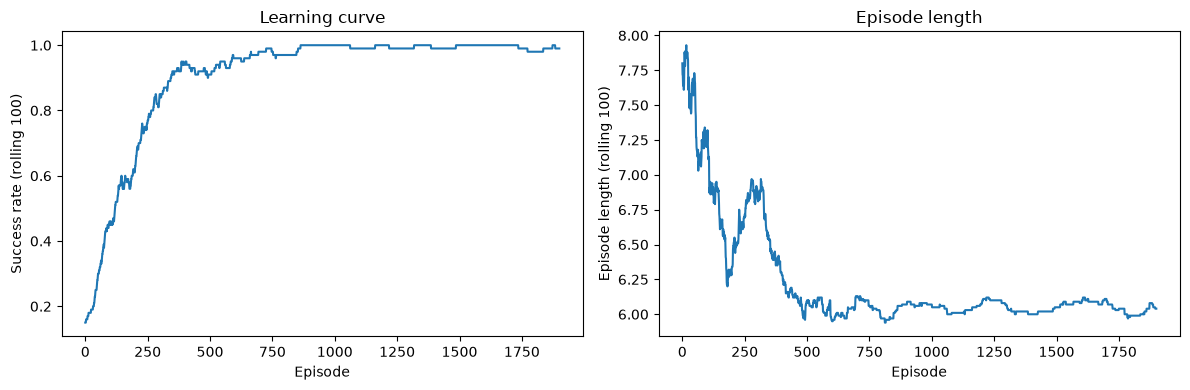

v < v <
v H v H
> v v H
H > > G


In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(rolling)
ax1.set_xlabel('Episode')
ax1.set_ylabel(f'Success rate (rolling {window})')
ax1.set_title('Learning curve')
ax2.plot(np.convolve(episode_lengths, np.ones(window) / window, mode='valid'))
ax2.set_xlabel('Episode')
ax2.set_ylabel(f'Episode length (rolling {window})')
ax2.set_title('Episode length')
plt.tight_layout()
plt.show()

# Show the greedy action in each square (S=start, F=frozen, H=hole, G=goal)
arrows = np.array(['<', 'v', '>', '^'])
grid = env.unwrapped.desc.astype(str)
policy = arrows[agent.q_table.argmax(axis=1)].reshape(grid.shape)
print('\n'.join(' '.join(p if g in 'SF' else g for g, p in zip(grow, prow)) for grow, prow in zip(grid, policy)))